## **Iris Classification**

This project involves classifying different species of flowers based on certain characteristics like the length and width of the Sepals and Petals.
This project was done to fufil my responsibilities as a data scientist Intern at Datatheon 

##### **Project Objectives**
* Preprocess the data (Data Cleaning, Outlier Dectection)
* EDA (Exploratory Data Analysis)
* Build the classification models, evaluate and deploy the best model

In [1]:
# import the necessary libraries 
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# Load the dataset 
data_path = "C:\\Users\\ADETUNJI ENIOLA\\Downloads\\iris.csv"
df = pd.read_csv(data_path)
df.head()

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


In [3]:
data_shape = df.shape
print(f"The dataset has {data_shape[0]} rows and {data_shape[1]} columns ")

The dataset has 150 rows and 5 columns 


## **Data Understanding and Preprocessing** 

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   sepal_length  150 non-null    float64
 1   sepal_width   150 non-null    float64
 2   petal_length  150 non-null    float64
 3   petal_width   150 non-null    float64
 4   species       150 non-null    object 
dtypes: float64(4), object(1)
memory usage: 6.0+ KB


In [5]:
df.describe()

,sepal_length,sepal_width,petal_length,petal_width
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333
std,0.828066,0.435866,1.765298,0.762238
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000


In [6]:
df.isnull().sum()

sepal_length    0
sepal_width     0
petal_length    0
petal_width     0
species         0
dtype: int64

In [7]:
dupes = df.duplicated().sum()
print(f"The data has {dupes} duplicate values.")

The data has 1 duplicate values.


In [8]:
# drop duplicates 
df = df.drop_duplicates()
#check 
dupes_new = df.duplicated().sum()
print(f"The data now has {dupes_new} duplicate values.")

The data now has 0 duplicate values.


#### ***Data Cleaning Summary***

* The data had one duplicate value and no null values 
* The duplicate values was dropped leaving the new dataset with 149 rows and 5 columns.

## **Outlier Detection**

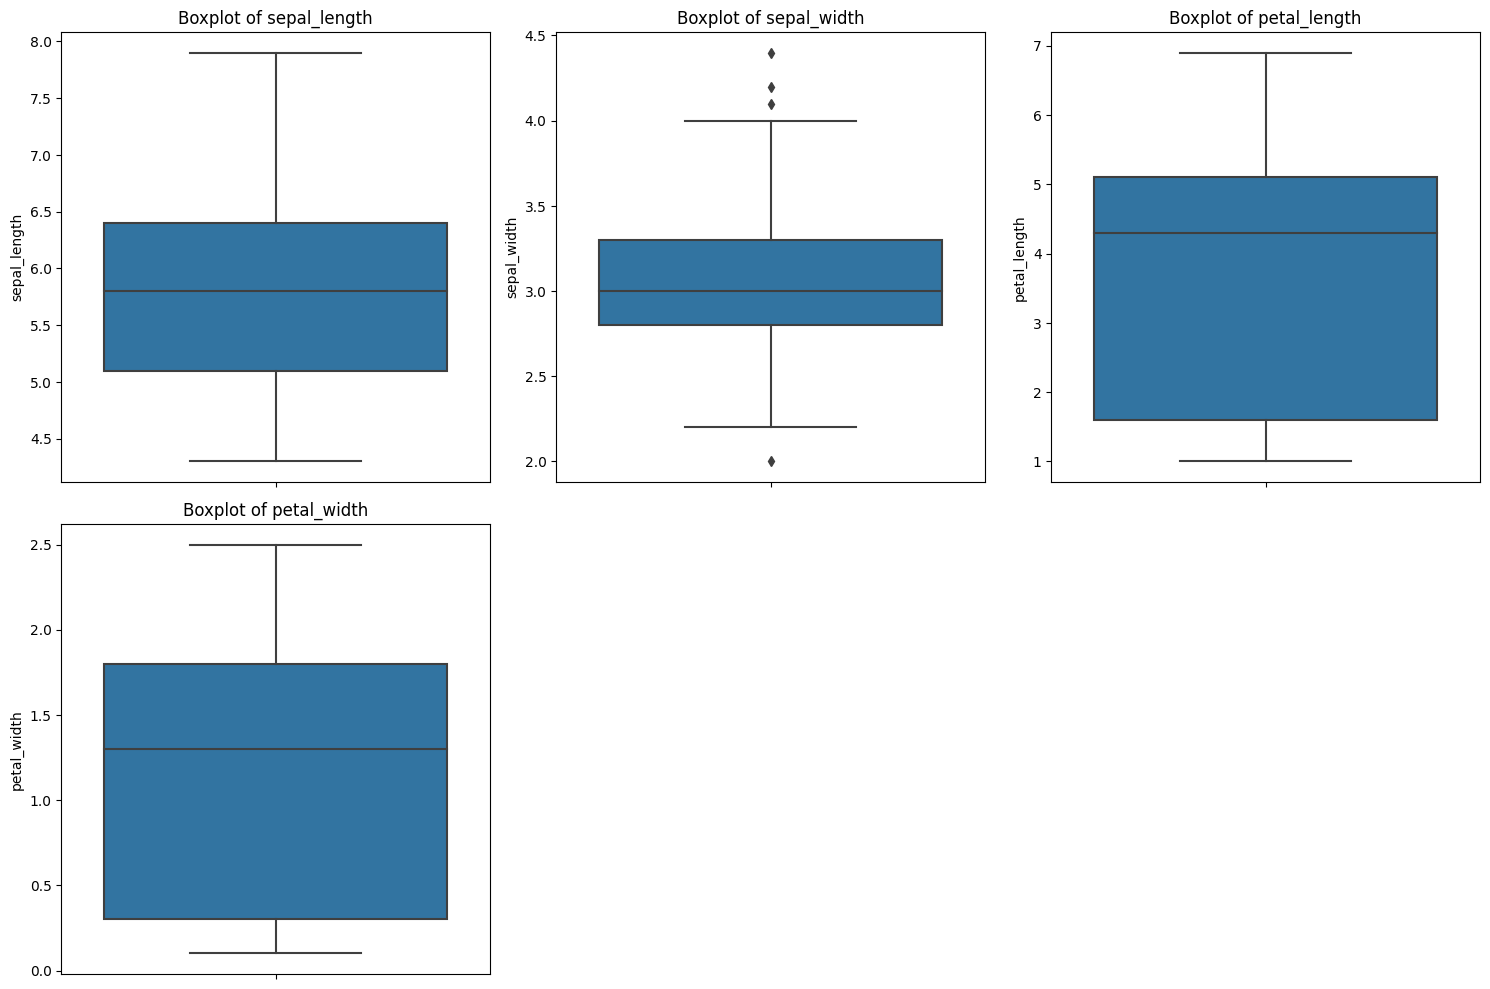

In [9]:
plt.figure(figsize=(15, 10))

for i, col in enumerate(df.drop(columns='species').columns, 1):   # enumerating numerical columns only
    plt.subplot(2, 3, i)
    sns.boxplot(y=df[col])
    plt.title(f'Boxplot of {col}')
    plt.ylabel(col)

plt.tight_layout()
plt.show()


### ***Outlier Observations (Insights)***

- The boxplots indicate the presence of potential outliers in most of the numerical features.
- The **petal_width**, **sepal_length** and **petal_length** columns  each have no noticebale potential outliers. 
- However, the **sepal_width** columns had a few outliers lying above and below the whiskers.

In [10]:
# Investigating outliers further 
Q1 = df["sepal_width"].quantile(0.25)
Q3 = df["sepal_width"].quantile(0.75)

IQR = Q3 - Q1 
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = df[
(df["sepal_width"] < lower_bound) |
(df["sepal_width"] > upper_bound)
]


outliers [["sepal_width", "species"]]

,sepal_width,species
15,4.4,setosa
32,4.1,setosa
33,4.2,setosa
60,2.0,versicolor


In [11]:
print("Lower bound:", lower_bound)
print("Upper bound:", upper_bound )

print("Detected outliers:")
print(outliers["sepal_width"])

Lower bound: 2.05
Upper bound: 4.05
Detected outliers:
15    4.4
32    4.1
33    4.2
60    2.0
Name: sepal_width, dtype: float64


In [12]:
print("Number of outliers:", len(outliers))
print(outliers["sepal_width"].sort_values())

Number of outliers: 4
60    2.0
32    4.1
33    4.2
15    4.4
Name: sepal_width, dtype: float64


The IQR method identified four potential outliers in the sepal_width column. 
Being flagged as an outlier doesn't mean these values are incorrect and since no evidence of data entry errors has been established, these observations will be retained for model development.

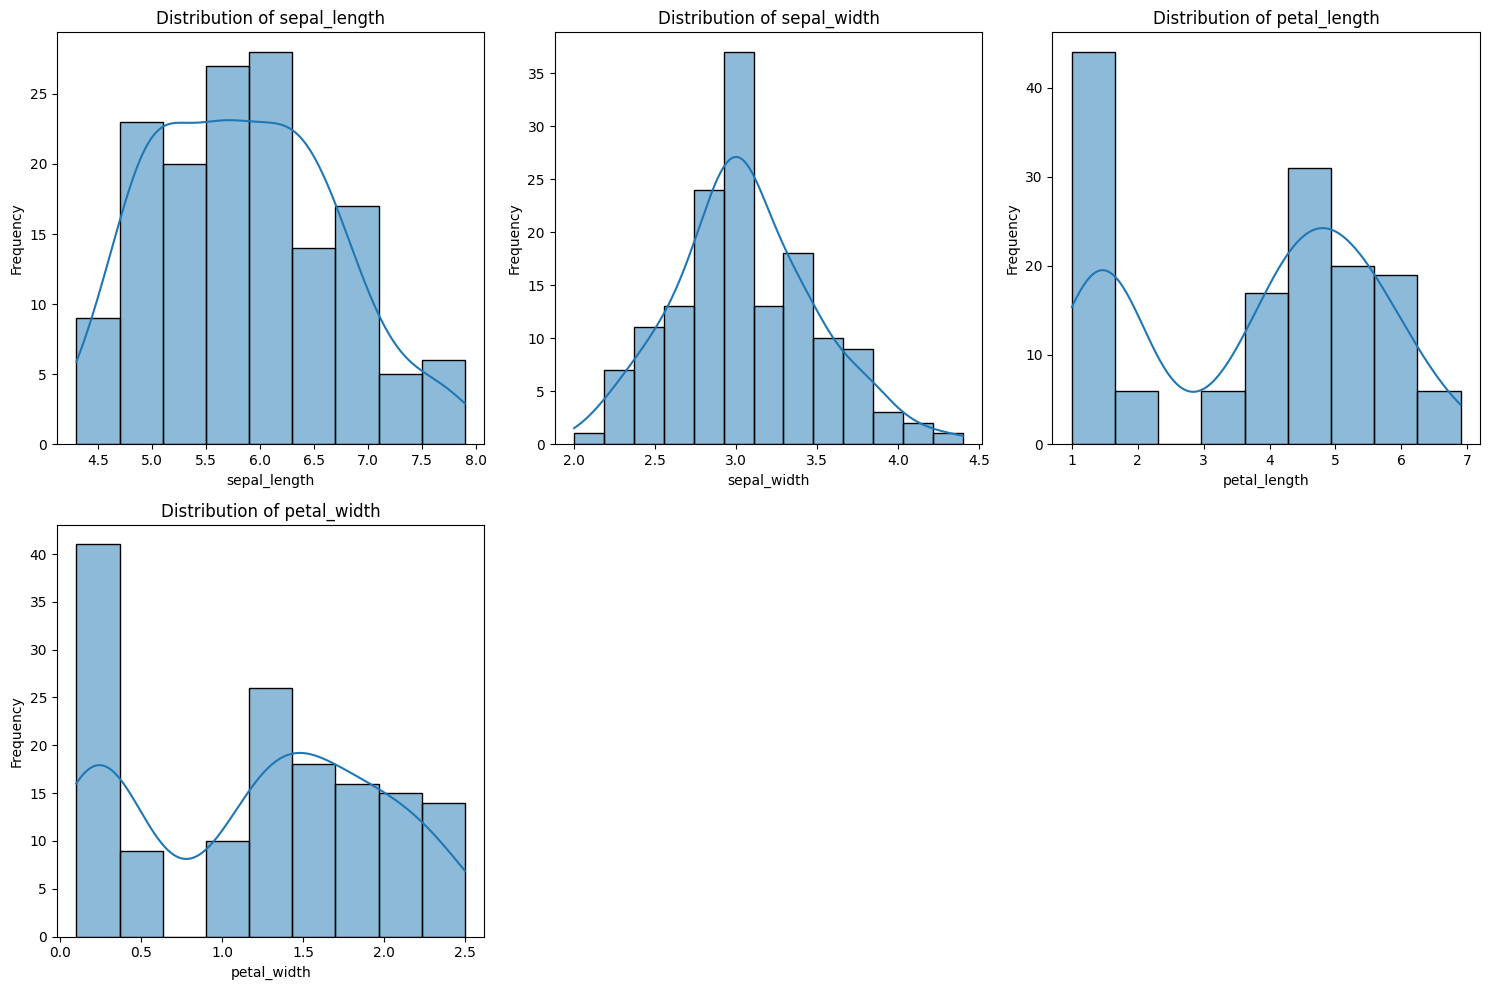

In [13]:
plt.figure(figsize=(15, 10))

for i, col in enumerate(df.drop(columns='species').columns, 1):
    plt.subplot(2, 3, i)
    sns.histplot(data=df, x=col, kde=True)
    plt.title(f'Distribution of {col}')
    plt.xlabel(col)
    plt.ylabel('Frequency')

plt.tight_layout()
plt.show()

- The various features in the dataset have varying distributions as well. The **sepal length** column has a moderately right skewed distribution with most data values between the range of **5.0** to **7.0**.
- The **sepal width** column shows a bell- shaped curve, suggesting that most data points cluster in the middle region with values between **3.0** to **3.5**.
- The **petal length** and the **petal width** column shows a zig-zag curve with most values clustered to the right ranging from values **4 to 6** for petal length and **1.5 to 2.5** for peta; width 

In [14]:
import scipy.stats as stats

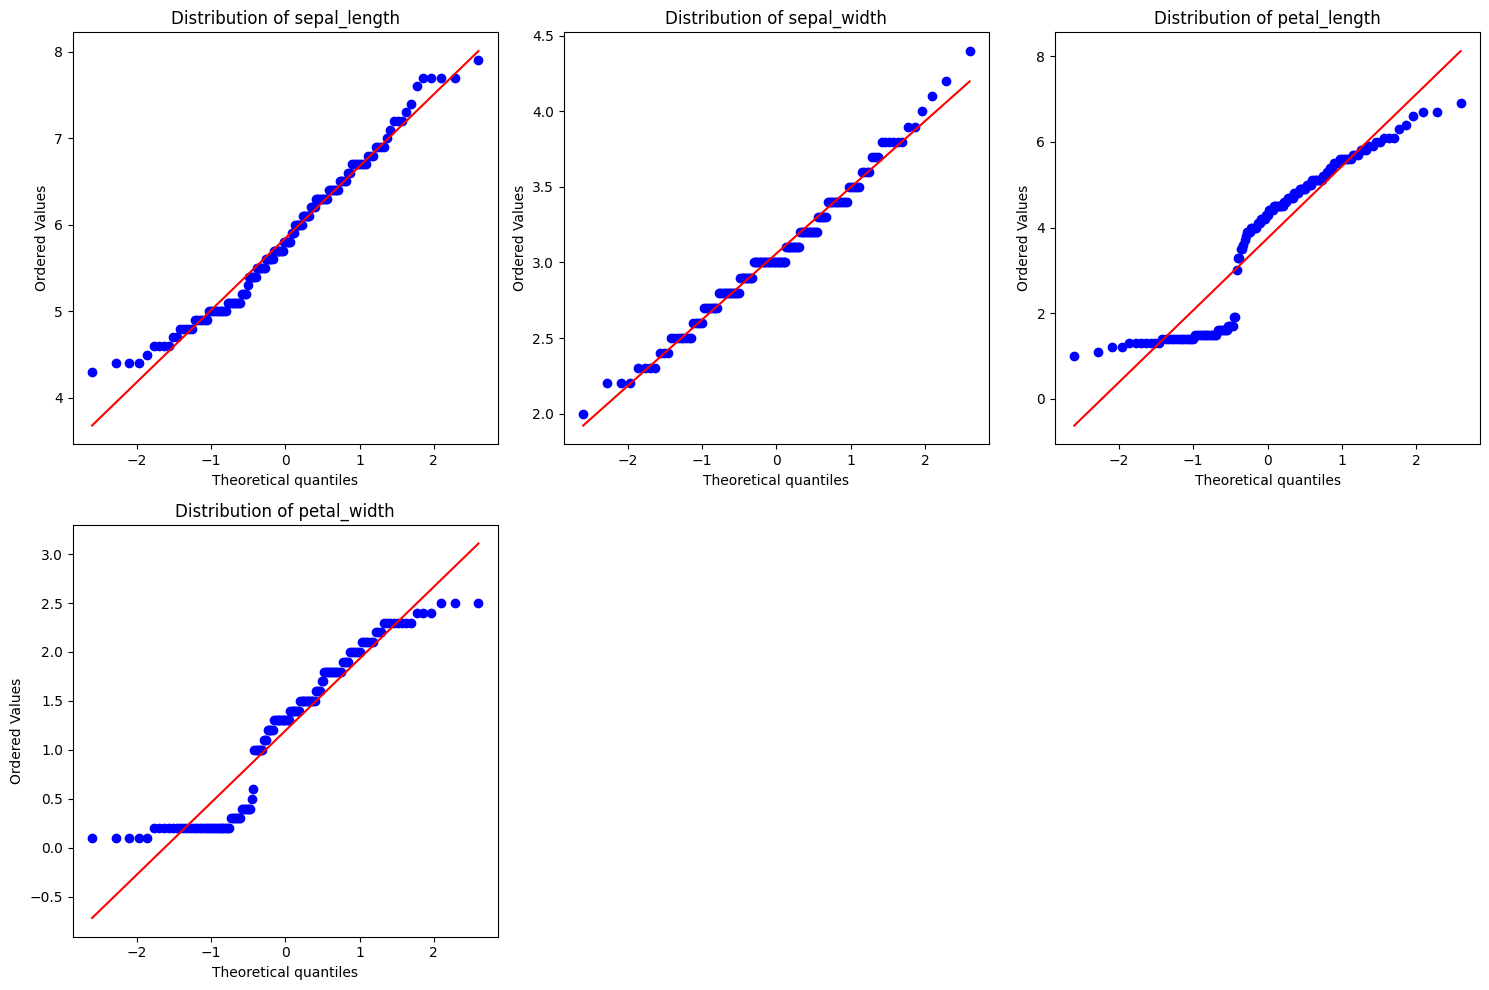

In [15]:
plt.figure(figsize=(15, 10))

for i, col in enumerate(df.drop(columns='species').columns, 1):
    plt.subplot(2, 3, i)
    stats.probplot(df[col], dist = "norm",plot = plt)
    plt.title(f'Distribution of {col}')

plt.tight_layout()
plt.show()

**Exploratory Data Analysis**

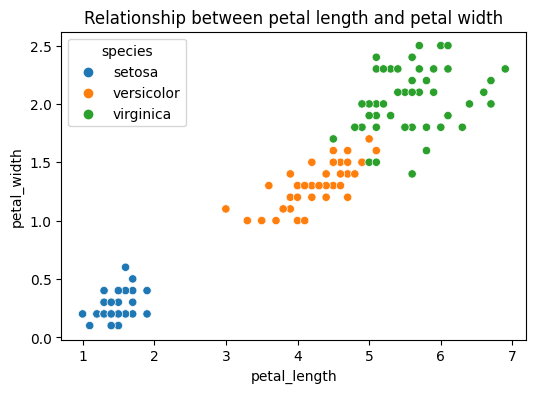

In [16]:
# Is petal length related to petal width ? 

plt.figure(figsize =(6, 4))
sns.scatterplot(data = df, x = "petal_length", y = "petal_width", hue = "species")
plt.title("Relationship between petal length and petal width")

plt.show()

**Insights**

The scatter plot shows a strong positive relationship between petal length and petal width. 
- As the petal length increases, the petal width generally increases as well.
- The different Iris species form distinct clusters with **versilcolor** overlapping **virginca**
- A clear positive correlation can be observed in the **setosa** and **versicolor** species while the **virginica** species has a moderate positive correlation. 

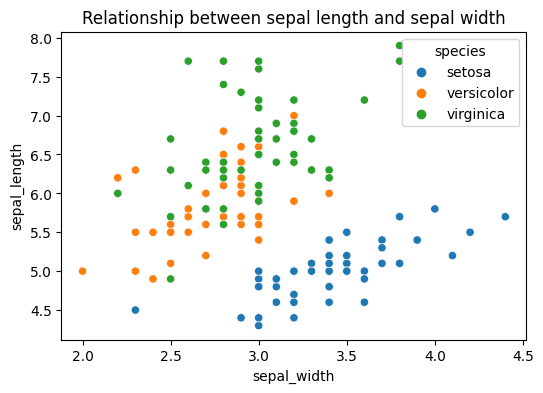

In [17]:
# Is sepal length related to sepal width ?

plt.figure(figsize = (6,4))

sns.scatterplot(data = df, x = "sepal_width",y = "sepal_length", hue = "species")
plt.title("Relationship between sepal length and sepal width")

plt.show()

**Insights**
- There's no clear relationship between the **sepal length** and the **sepal_width** of the different Iris species 

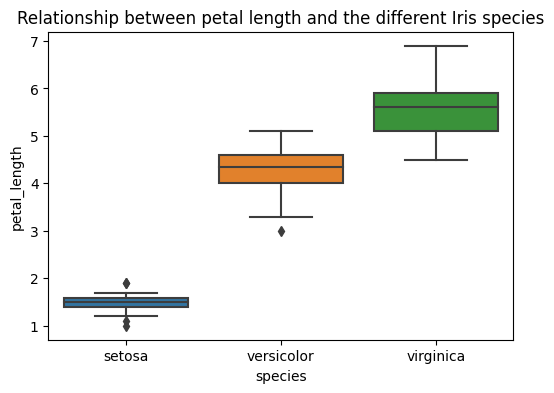

In [18]:
# Does Petal length differ across iris species ? 

plt.figure(figsize = (6,4))

sns.boxplot(data = df, x = "species", y = "petal_length")
plt.title("Relationship between petal length and the different Iris species")

plt.show()

**Insight**

- There's a disntinct variation in the petal lengths of the different Iris species 
- The **Virgnica species** has the highest median petal length, this followed by **versicolor** with **setosa** having the lowest petal length 
- This may suggest that petal length is an important feature in determining the Iris species  

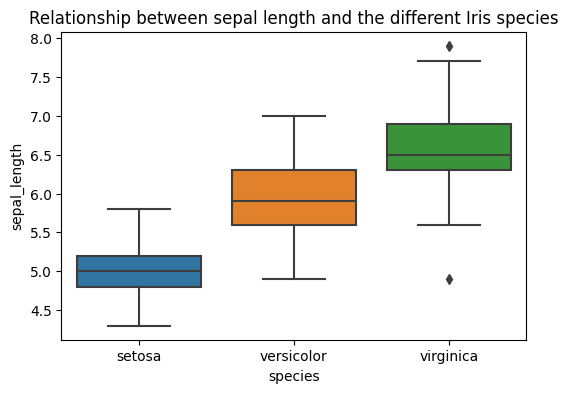

In [19]:
# Does Sepal length differ across iris species ? 

plt.figure(figsize = (6,4))

sns.boxplot(data = df, x = "species", y = "sepal_length")
plt.title("Relationship between sepal length and the different Iris species")

plt.show()

**Insight**

- There's a disntinct variation in the sepal lengths of the different Iris species 
- The **Virgnica species** has the highest median sepal length, this followed by **versicolor** with **setosa** having the lowest sepal length 
- This may suggest that sepal length is an important feature in determining the Iris species  

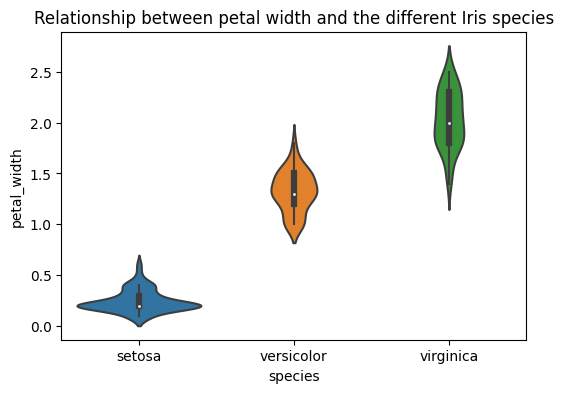

In [20]:
# Does petal width differ across iris species ?

plt.figure(figsize = (6,4))
sns.violinplot(data = df, x = "species", y = "petal_width")
plt.title("Relationship between petal width and the different Iris species")

plt.show()

**Insights**
- Petal widths differ considerably by species 
- **Setosa** has the smallest petal width, followed by **Versicolor** and then **Virginica**
- There's an overlap in petal widths between the **versicolor** and **virginica** species 
- This suggests that petal width may be an important feature for predicting Iris species.

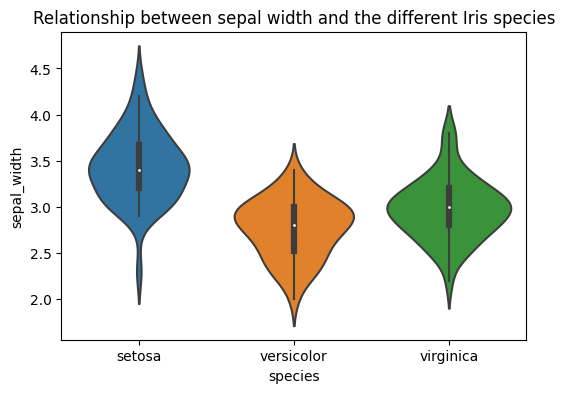

In [21]:
# Does sepal width differ across iris species ?

plt.figure(figsize = (6,4))
sns.violinplot(data = df, x = "species", y = "sepal_width")
plt.title("Relationship between sepal width and the different Iris species")

plt.show()

**Insights**
- Sepal widths differ considerably by species 
- **Setosa** has the highest sepal width, followed by **Versicolor** and then **Virginica**
- There's a strong overlap in sepal widths between the **versicolor** and **virginica** species 
- This suggests that sepal width may be an important feature for predicting Iris species. However, there might be difficulty differentiating between versicolor and virginica using sepal widths alone.

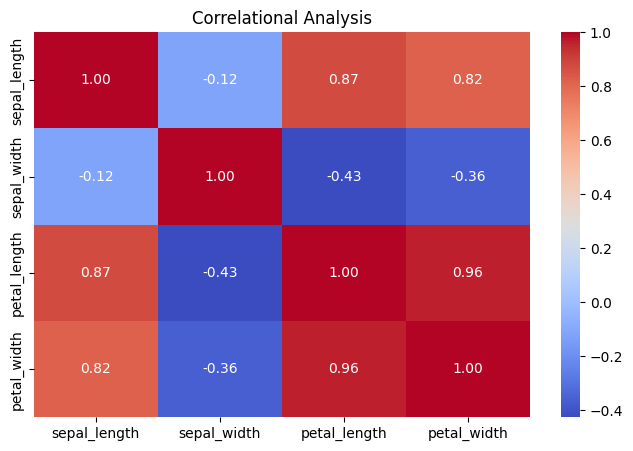

In [22]:
# Correlational Analysis: How do all 4 features relate to one another ?

num_features = df.drop(columns= "species")

correlation = num_features.corr()

plt.figure(figsize=(8, 5))
sns.heatmap(correlation, annot = True, cmap = "coolwarm", fmt = ".2f")
plt.title("Correlational Analysis")

plt.show()

**Insights**
- **Sepal length** has a strong positive correlation with **Petal width and Petal length** and a weak negative correlation with **Sepal width**
- **Sepal width** has a weak negative correlation with the rest of the features.
- **Petal length and Petal width** have a strong positive correlation with all other features asides **Sepal width**
- This suggests that **Sepal width** may be the least important feature when predicting Iris species.

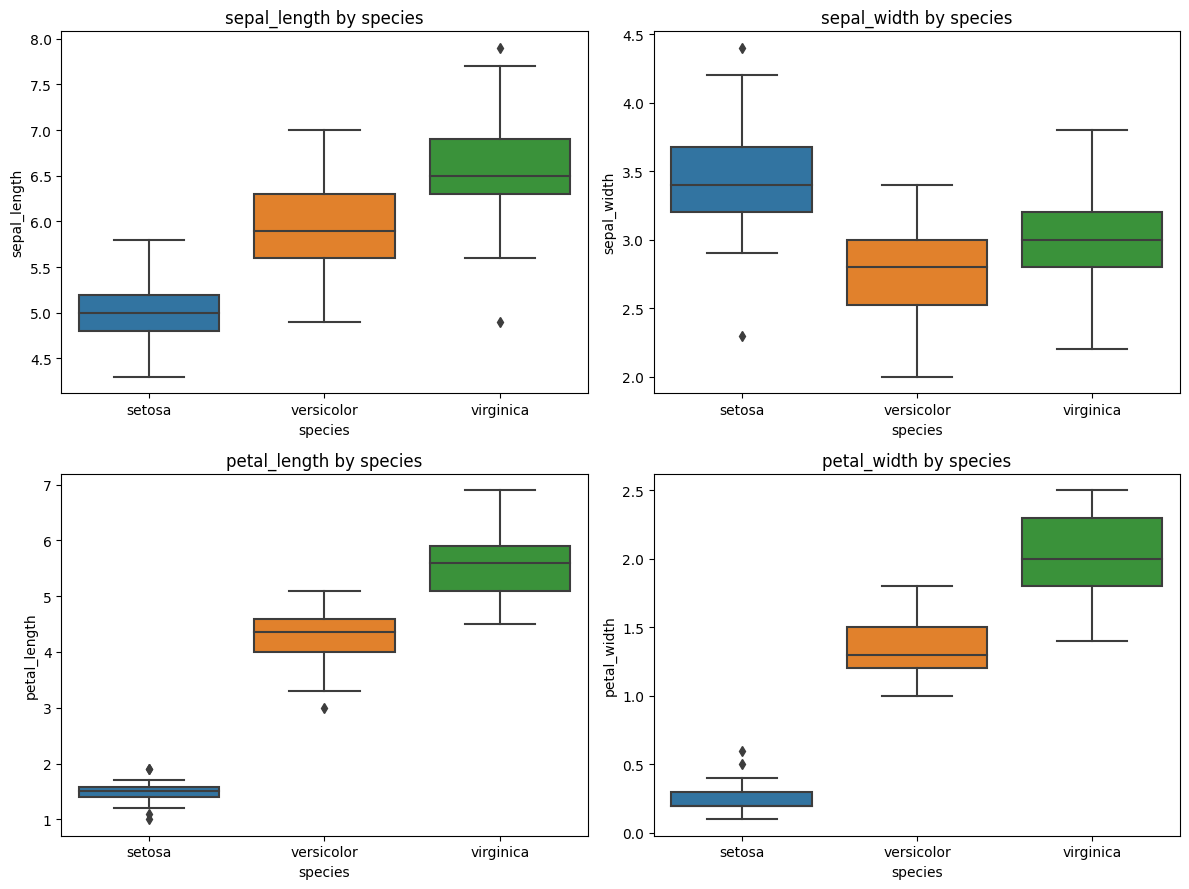

In [23]:
# Which features appear most useful for distinguishing the species 

fig, axes = plt.subplots(2,2,figsize =(12,9))

features = ["sepal_length", "sepal_width","petal_length","petal_width"]

for ax, feature in zip(axes.flat, features):
  sns.boxplot(data = df, x = "species",y = feature, ax = ax)
  ax.set_title(f"{feature} by species")


plt.tight_layout()
plt.show()

**Model Development**

In [24]:
# Define features 

x = df.drop(columns="species")
y = df["species"]

In [25]:
print("Features shape:", x.shape)
print("Target shape:", y.shape)

Features shape: (149, 4)
Target shape: (149,)


In [26]:
from sklearn.model_selection import train_test_split 

x_train, x_test, y_train, y_test = train_test_split(x,y,test_size = 0.2, random_state = 42, stratify = y)

print("Training Features:", x_train.shape)
print("Testing Features:", x_test.shape)
print("Training Target:", y_train.shape)
print("Testing Target:", y_test.shape)

Training Features: (119, 4)
Testing Features: (30, 4)
Training Target: (119,)
Testing Target: (30,)


In [27]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier

# Logistic Regression Pipeline 

logistic_pipeline = Pipeline([("scaler", StandardScaler()), ("model", LogisticRegression(max_iter = 1000))])

#Decision Tree Pipeline
tree_pipeline = Pipeline ([("scaler:",StandardScaler()), ("model", DecisionTreeClassifier(random_state = 42))])

In [28]:
# Train the model 

logistic_pipeline.fit(x_train,y_train)
tree_pipeline.fit(x_train,y_train)

,steps,"[('scaler:', ...), ('model', ...)]"
,transform_input,None
,memory,None
,verbose,False
,copy,True
,with_mean,True
,with_std,True
,criterion,'gini'
,splitter,'best'
,max_depth,None
,min_samples_split,2


In [29]:
y_pred_logistic = logistic_pipeline.predict(x_test)
y_pred_tree = tree_pipeline.predict(x_test)

In [30]:
from sklearn.metrics import(
  accuracy_score,
  precision_score,
  recall_score,
  f1_score,
  classification_report
)

# Logistic regression evaluation 
logistic_metrics = {
  "Accuracy": accuracy_score(y_test, y_pred_logistic),
  "Precision": precision_score(y_test, y_pred_logistic, average = "macro", zero_division = 0),
  "Recall": recall_score(y_test, y_pred_logistic,average = "macro", zero_division = 0),
  "F1-score": f1_score(y_test, y_pred_logistic, average = "macro", zero_division = 0)
}

# Decision Tree Evaluation 

tree_metrics = {
  "Accuracy": accuracy_score(y_test, y_pred_tree),
  "Precision": precision_score(y_test, y_pred_tree, average = "macro", zero_division = 0),
  "Recall": recall_score(y_test, y_pred_tree,average = "macro", zero_division = 0),
  "F1-score": f1_score(y_test, y_pred_tree, average = "macro", zero_division = 0)
}

In [31]:
print("Logistic Regression:")
for metric, score in logistic_metrics.items():
  print(f"{metric}: {score:.3f}")

print("Decision Tree:")
for metric, score in tree_metrics.items():
  print(f"{metric}: {score:.3f}")

Logistic Regression:
Accuracy: 0.933
Precision: 0.933
Recall: 0.933
F1-score: 0.933
Decision Tree:
Accuracy: 0.933
Precision: 0.933
Recall: 0.933
F1-score: 0.933


In [32]:
print("LOGISTIC REGRESSION REPORT")
print(classification_report(y_test, y_pred_logistic,zero_division= 0))

print("DECISION TREE REPORT")
print(classification_report(y_test, y_pred_logistic,zero_division= 0))

LOGISTIC REGRESSION REPORT
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30

DECISION TREE REPORT
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30



In [33]:
comparison = pd.DataFrame({
  "LogisticRegression": logistic_metrics,
  "Decision Tree": tree_metrics
}). T

comparison

,Accuracy,Precision,Recall,F1-score
LogisticRegression,0.933333,0.933333,0.933333,0.933333
Decision Tree,0.933333,0.933333,0.933333,0.933333


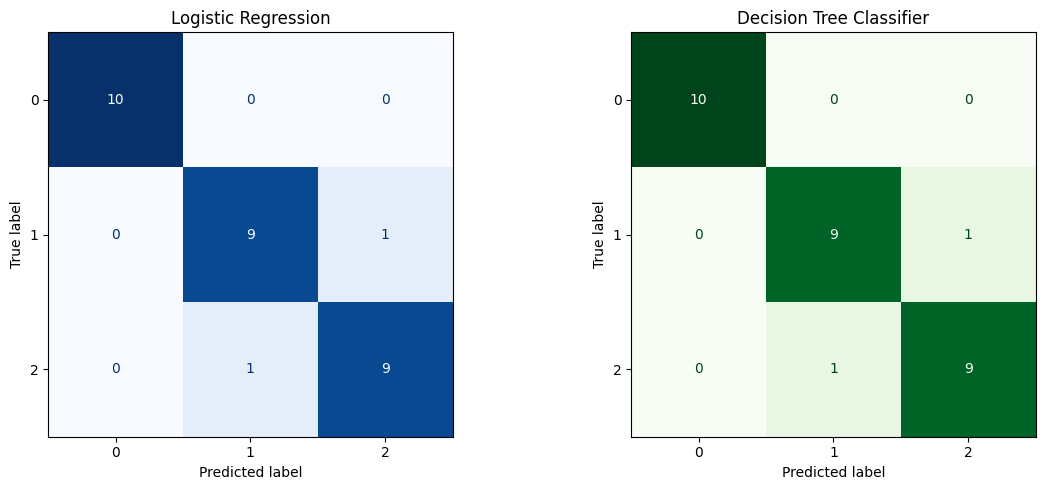

In [34]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

#calculate confusion matrices
cm_logistic = confusion_matrix(y_test, y_pred_logistic)
cm_tree = confusion_matrix(y_test, y_pred_tree)

#Create two separate plots
fig, axes = plt.subplots(1,2,figsize = (12,5))

#Logistic Regression 

disp_logistic = ConfusionMatrixDisplay(
  confusion_matrix = cm_logistic
)
disp_logistic.plot(
  ax = axes[0],
  cmap = "Blues",
  colorbar = False
)
axes[0].set_title("Logistic Regression")

#Tree regression 

disp_tree = ConfusionMatrixDisplay(
  confusion_matrix = cm_tree
)
disp_tree.plot(
  ax = axes[1],
  cmap = "Greens",
  colorbar = False
)
axes[1].set_title("Decision Tree Classifier")

plt.tight_layout()
plt.show()

In [35]:
# Prediction Comparison

prediction_comparison = pd.DataFrame({
  "Actual": y_test,
  "Logistic Regression": y_pred_logistic,
  "Decision Tree": y_pred_tree
}) 

prediction_comparison["Models_Agree"] = (
  prediction_comparison["Logistic Regression"]
  == prediction_comparison["Decision Tree"]
)

prediction_comparison

,Actual,Logistic Regression,Decision Tree,Models_Agree
69,versicolor,versicolor,versicolor,True
66,versicolor,versicolor,versicolor,True
141,virginica,virginica,virginica,True
7,setosa,setosa,setosa,True
147,virginica,virginica,virginica,True
57,versicolor,versicolor,versicolor,True
84,versicolor,versicolor,versicolor,True
28,setosa,setosa,setosa,True
138,virginica,virginica,virginica,True
127,virginica,virginica,virginica,True


In [36]:
print("Number of Matching Predictions:",(y_pred_logistic == y_pred_tree).sum())
print("Total test samples:", y_test)

Number of Matching Predictions: 30
Total test samples: 69     versicolor
66     versicolor
141     virginica
7          setosa
147     virginica
57     versicolor
84     versicolor
28         setosa
138     virginica
127     virginica
20         setosa
42         setosa
18         setosa
93     versicolor
140     virginica
22         setosa
77     versicolor
14         setosa
107     virginica
38         setosa
63     versicolor
134     virginica
41         setosa
10         setosa
96     versicolor
51     versicolor
104     virginica
116     virginica
132     virginica
56     versicolor
Name: species, dtype: object


In [37]:
print(x.columns.tolist())

['sepal_length', 'sepal_width', 'petal_length', 'petal_width']


c:\Users\ADETUNJI ENIOLA\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


ValueError: could not convert string to float: 'setosa'

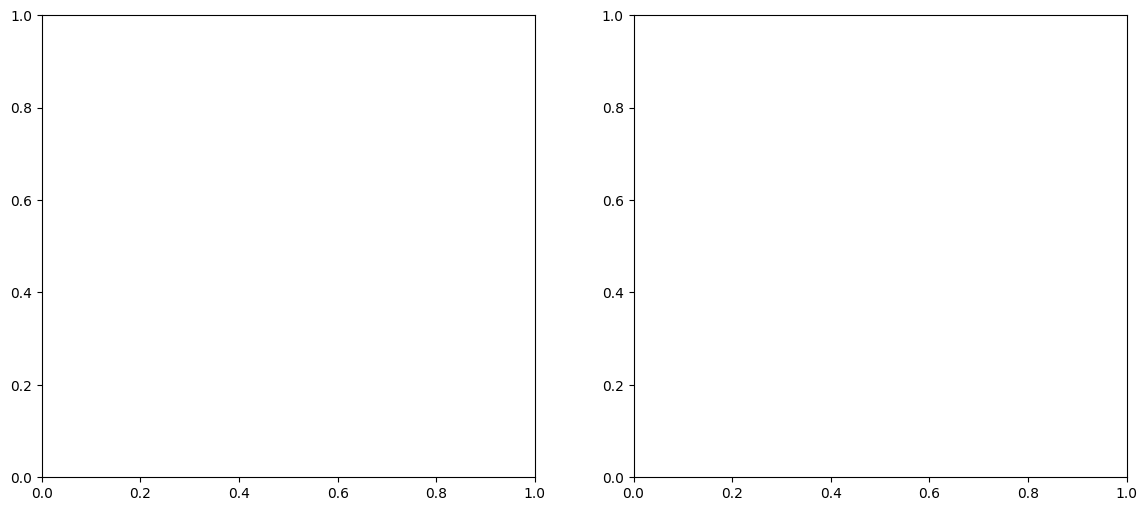

In [38]:

import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.pipeline import make_pipeline

# Select two features
x_2d = x[['petal_length', 'petal_width']]

# Split the data
x_train_2d, x_test_2d, y_train_2d, y_test_2d = train_test_split(
    x_2d, y, test_size=0.2, random_state=42, stratify=y
)

# Create and train the two models
logistic_2d = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=1000)
)

tree_2d = DecisionTreeClassifier(random_state=42)

logistic_2d.fit(x_train_2d, y_train_2d)
tree_2d.fit(x_train_2d, y_train_2d)

# Create a grid across the feature space
x_min, x_max = (
    x_2d['petal_length'].min() - 0.5,
    x_2d['petal_length'].max() + 0.5
)

y_min, y_max = (
    x_2d['petal_width'].min() - 0.5,
    x_2d['petal_width'].max() + 0.5
)

xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 300),
    np.linspace(y_min, y_max, 300)
)

grid = np.c_[xx.ravel(), yy.ravel()]

# Plot both decision boundaries
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

models = [
    ("Logistic Regression", logistic_2d),
    ("Decision Tree", tree_2d)
]

for ax, (name, model) in zip(axes, models):
    predictions = model.predict(grid)

    ax.contourf(
        xx, yy,
        predictions.reshape(xx.shape),
        alpha=0.3,
        cmap='viridis'
    )

    for species in np.unique(y_train_2d):
        mask = y_train_2d.to_numpy() == species

        ax.scatter(
            x_train_2d.loc[mask, 'petal_length'],
            x_train_2d.loc[mask, 'petal_width'],
            label=f"Species {species}",
            edgecolor='black',
            s=40
        )

    ax.set_title(name)
    ax.set_xlabel('Petal Length')
    ax.set_ylabel('Petal Width')
    ax.legend()

plt.tight_layout()
plt.show()
